<a href="https://colab.research.google.com/github/Zsombic007/car_price_prediction/blob/main/car_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# common
import os
import numpy as np
import pandas as pd

# encoder
from sklearn.preprocessing import LabelEncoder

# splitting the data
from sklearn.model_selection import train_test_split

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# model
from sklearn.ensemble import RandomForestRegressor

# evaluation metrics
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_score

# fine tuning
from sklearn.model_selection import GridSearchCV

In [ ]:
data = pd.read_csv("/content/drive/MyDrive/python_ai/car_price.csv")

In [ ]:
data

,Unnamed: 0,car_name,car_prices_in_rupee,kms_driven,fuel_type,transmission,ownership,manufacture,engine,Seats
0,0,Jeep Compass 2.0 Longitude Option BSIV,10.03 Lakh,"86,226 kms",Diesel,Manual,1st Owner,2017,1956 cc,5 Seats
1,1,Renault Duster RXZ Turbo CVT,12.83 Lakh,"13,248 kms",Petrol,Automatic,1st Owner,2021,1330 cc,5 Seats
2,2,Toyota Camry 2.5 G,16.40 Lakh,"60,343 kms",Petrol,Automatic,1st Owner,2016,2494 cc,5 Seats
3,3,Honda Jazz VX CVT,7.77 Lakh,"26,696 kms",Petrol,Automatic,1st Owner,2018,1199 cc,5 Seats
4,4,Volkswagen Polo 1.2 MPI Highline,5.15 Lakh,"69,414 kms",Petrol,Manual,1st Owner,2016,1199 cc,5 Seats
...,...,...,...,...,...,...,...,...,...,...
5507,5507,BMW X1 sDrive 20d xLine,28.90 Lakh,"45,000 kms",Diesel,Automatic,1st Owner,2018,2995 cc,7 Seats
5508,5508,BMW M Series M4 Coupe,64.90 Lakh,"29,000 kms",Petrol,Automatic,2nd Owner,2015,1968 cc,5 Seats
5509,5509,Jaguar XF 2.2 Litre Luxury,13.75 Lakh,"90,000 kms",Diesel,Automatic,2nd Owner,2013,2755 cc,5 Seats
5510,5510,BMW 7 Series 730Ld,29.90 Lakh,"79,000 kms",Diesel,Automatic,3rd Owner,2015,2967 cc,6 Seats


In [ ]:
data = data.drop(columns=["Unnamed: 0"], axis=1)

In [ ]:
data.rename(columns={'car_name': 'model'}, inplace=True)
data['manufacturer'] = data['model'].map(lambda x: str(x).strip().split(" ")[0])
data['model'] = data['model'].map(lambda x: str(x).strip().split(" ")[1])

In [ ]:
data['kms_driven'] = data['kms_driven'].map(lambda x: x.rstrip(' kms'))
data['kms_driven'] = data['kms_driven'].map(lambda x: x.replace(',', ''))
data['kms_driven'] = pd.to_numeric(data['kms_driven'])

In [ ]:
data['engine'] = data['engine'].map(lambda x: x.rstrip(' cc'))
data['engine'] = pd.to_numeric(data['engine'])

In [ ]:
data['Seats'] = pd.to_numeric(data['Seats'].map(lambda x: x.rstrip(' Seats')))

In [ ]:
data[['price', 'multiply']] = data['car_prices_in_rupee'].str.split(' ', expand=True)
data.drop('car_prices_in_rupee', axis=1, inplace=True)
# converting multiply column into numerical value
data['multiply']=data['multiply'].str.replace('Lakh','100000')
data['multiply']=data['multiply'].str.replace('Crore','10000000')
data['multiply'] = pd.to_numeric(data['multiply'])
# getting price in actual numbers
data['price']=data['price'].str.replace(',','')
data['price'] = pd.to_numeric(data['price'])
data['price'] = data['price'] * data['multiply'] * 0.012 # converting ruppe to $
# remove the multiply column
data = data.drop(columns=["multiply"], axis=1)

In [ ]:
data = data.iloc[:,[8,0,5,1,6,2,3,7,4,9]]

In [ ]:
data["ownership"] =pd.to_numeric(data["ownership"].map(lambda x: str(x)[0]))

In [ ]:
data

,manufacturer,model,manufacture,kms_driven,engine,fuel_type,transmission,Seats,ownership,price
0,12,47,2017,86226,1956,1,1,5,1,12036.0
1,26,54,2021,13248,1330,4,0,5,1,15396.0
2,29,39,2016,60343,2494,4,0,5,1,19680.0
3,8,99,2018,26696,1199,4,0,5,1,9324.0
4,30,138,2016,69414,1199,4,1,5,1,6180.0
...,...,...,...,...,...,...,...,...,...,...
5507,1,204,2018,45000,2995,1,0,7,1,34680.0
5508,1,113,2015,29000,1968,4,0,5,2,77880.0
5509,11,213,2013,90000,2755,1,0,5,2,16500.0
5510,1,4,2015,79000,2967,1,0,6,3,35880.0


In [ ]:
data.dtypes

manufacturer     object
model            object
manufacture       int64
kms_driven        int64
engine            int64
fuel_type        object
transmission     object
Seats             int64
ownership         int64
price           float64
dtype: object

In [ ]:
labelencoder = LabelEncoder()
# encoding the car's manufacturer with label encoder
data['manufacturer'] = labelencoder.fit_transform(data['manufacturer'])
# encoding the car's model with label encoder
data['model'] = labelencoder.fit_transform(data['model'])
# encoding the car's fuel type with label encoder
data['fuel_type'] = labelencoder.fit_transform(data['fuel_type'])
# encoding the car's transmission with label encoder
data['transmission'] = labelencoder.fit_transform(data['transmission'])


In [ ]:
data.dropna(inplace = True)

In [ ]:
X = data.drop('price', axis=1)
y = data['price']

In [ ]:
X.head(), X.shape

(   manufacturer  model  manufacture  kms_driven  engine  fuel_type  \
 0            12     47         2017       86226    1956          1   
 1            26     54         2021       13248    1330          4   
 2            29     39         2016       60343    2494          4   
 3             8     99         2018       26696    1199          4   
 4            30    138         2016       69414    1199          4   
 
    transmission  Seats  ownership  
 0             1      5          1  
 1             0      5          1  
 2             0      5          1  
 3             0      5          1  
 4             1      5          1  ,
 (5389, 9))

In [ ]:
y.head(), y.shape

(0    12036.0
 1    15396.0
 2    19680.0
 3     9324.0
 4     6180.0
 Name: price, dtype: float64,
 (5389,))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((4311, 9), (1078, 9), (4311,), (1078,))

In [ ]:
data.isnull().sum()


manufacturer    0
model           0
manufacture     0
kms_driven      0
engine          0
fuel_type       0
transmission    0
Seats           0
ownership       0
price           0
dtype: int64

In [ ]:
regr = RandomForestRegressor(n_estimators=1500, max_depth=50, random_state=42)
regr.fit(X_train, y_train.values.ravel())
predictions = regr.predict(X_test)

In [ ]:
regr.score(X_train, y_train)

0.9812783602710539

In [ ]:
import math

In [ ]:
mse = math.sqrt(mean_squared_error(y_test.values.ravel(), predictions))
mse

6841.92371278687

In [ ]:
r2 = r2_score(y_test.values.ravel(), predictions)
r2

0.9170138629463516

In [ ]:
mae = mean_absolute_error(y_test.values.ravel(), predictions)
mae

2555.643851020408

In [ ]:
from sklearn.dummy import DummyRegressor


In [ ]:
dr = DummyRegressor(strategy="median",)

In [ ]:
dr.fit(X_train, y_train)
predictions_dr = dr.predict(X_test)

In [ ]:
mse = math.sqrt(mean_squared_error(y_test.values.ravel(), predictions_dr))
mse

24853.124002034077

In [ ]:
r2 = r2_score(y_test.values.ravel(), predictions_dr)
r2

-0.09499230530811364

In [ ]:
mae = mean_absolute_error(y_test.values.ravel(), predictions_dr)
mae

9807.016697588126

In [ ]:
from keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten

In [ ]:
model = Sequential()
model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))  # Input layer
model.add(Dense(32, activation='relu'))  # Hidden layer
model.add(Dense(1))  # Output layer (single value for regression)

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                640       
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 1)                 33        
                                                                 
Total params: 2753 (10.75 KB)
Trainable params: 2753 (10.75 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
model.compile(loss = "mean_squared_error",optimizer = "adam", metrics = ["AUC"])


In [ ]:
model.fit(X_train, y_train, epochs=25, batch_size=1, verbose=1)

Epoch 1/25
4311/4311 [==============================] - 21s 4ms/step - loss: 554765312.0000 - auc: 0.0000e+00
Epoch 2/25
4311/4311 [==============================] - 15s 3ms/step - loss: 515677920.0000 - auc: 0.0000e+00
Epoch 3/25
4311/4311 [==============================] - 14s 3ms/step - loss: 509366432.0000 - auc: 0.0000e+00
Epoch 4/25
4311/4311 [==============================] - 15s 3ms/step - loss: 507843840.0000 - auc: 0.0000e+00
Epoch 5/25
4311/4311 [==============================] - 15s 3ms/step - loss: 507879008.0000 - auc: 0.0000e+00
Epoch 6/25
4311/4311 [==============================] - 15s 3ms/step - loss: 506843200.0000 - auc: 0.0000e+00
Epoch 7/25
4311/4311 [==============================] - 15s 3ms/step - loss: 506069408.0000 - auc: 0.0000e+00
Epoch 8/25
4311/4311 [==============================] - 15s 4ms/step - loss: 507756384.0000 - auc: 0.0000e+00
Epoch 9/25
4311/4311 [==============================] - 16s 4ms/step - loss: 505256064.0000 - auc: 0.0000e+00
Epoch 10/2

In [ ]:
from sklearn.metrics import mean_squared_error


In [ ]:
y_pred = model.predict(X_test)

34/34 [==============================] - 0s 1ms/step


In [ ]:
mse = mean_squared_error(y_test, y_pred)
math.sqrt(mse)

22749.7754239506

In [ ]:
y_pred

array([[ 9575.481],
       [17986.072],
       [14627.373],
       ...,
       [11546.847],
       [15886.237],
       [11565.927]], dtype=float32)

In [ ]:
import matplotlib.pyplot as plt


In [ ]:
X_test.shape, y_test.shape, y_pred.shape, predictions.shape

((9, 1078), (1078,), (1078, 1), (1078,))

In [ ]:
X_test = X_test.T

Text(0, 0.5, 'Prices')

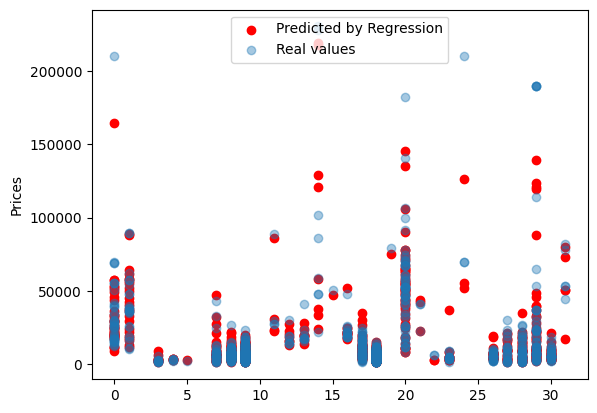

In [ ]:
plt.scatter(X_test[0], predictions, color = "red")
#plt.scatter(X_test[0], y_pred, color = "green")
plt.scatter(X_test[0], y_test, alpha = 0.4)
plt.legend(["Predicted by Regression", "Real values"],loc = "upper center")
plt.ylabel("Prices")

Text(0, 0.5, 'Price')

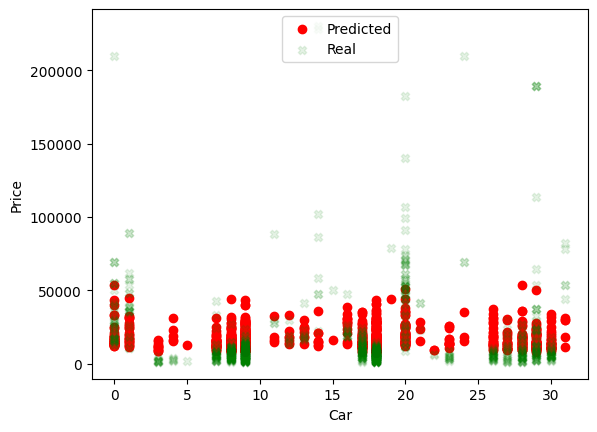

In [ ]:
plt.scatter(X_test[0],y_pred, color ="red", alpha=1.0)
plt.scatter(X_test[0],y_test, alpha = 0.1, color = "green", marker = "X")
plt.legend(["Predicted", "Real"],loc = "upper center")
plt.xlabel("Car")
plt.ylabel("Price")

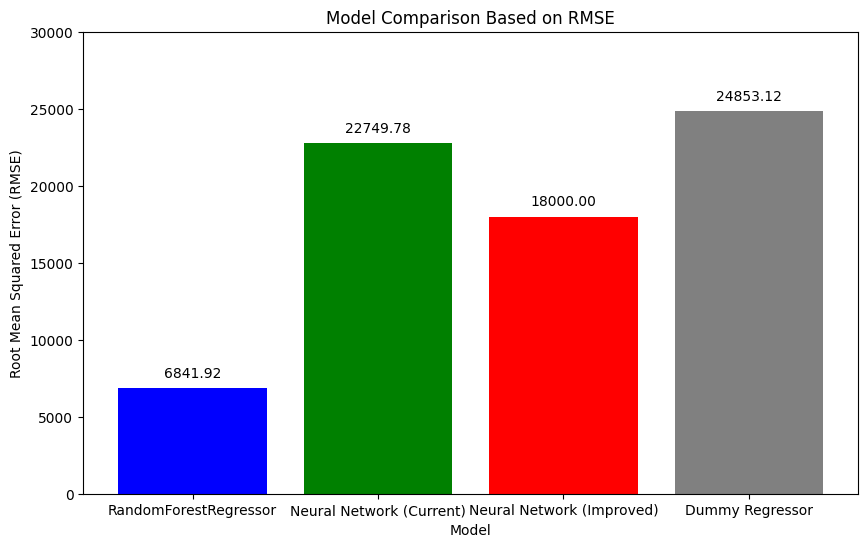

In [ ]:
# Assuming these are your RMSE values for the models
models = ['RandomForestRegressor', 'Neural Network (Current)', 'Neural Network (Improved)', 'Dummy Regressor']
rmse_values = [6841.92371278687, 22749.7754239506, 18000, 24853.124002034077]  # Add the RMSE for improved NN after training

# Create a bar chart
plt.figure(figsize=(10, 6))
plt.bar(models, rmse_values, color=['blue', 'green', 'red', 'grey'])
plt.xlabel('Model')
plt.ylabel('Root Mean Squared Error (RMSE)')
plt.title('Model Comparison Based on RMSE')
plt.ylim(0, 30000)  # Adjust the y-axis limit as needed

# Annotate the bars with the RMSE values
for i, value in enumerate(rmse_values):
    plt.text(i, value + 500, f'{value:.2f}', ha='center', va='bottom')

# Show the plot
plt.show()